# Project 02: Seed-free graph matching
**Main method:** bootstrap percolation (fingerprint seeds -> greedy percolation -> re-seed -> reject).
**Compared against:** (1) fingerprint + Hungarian, (2) IsoRank, (3) Frank-Wolfe QAP (FAQ).
All algorithms live in `seedfree.py` (numpy/scipy only, own implementations). Protocol: tune on Train only, confirm once on Val, freeze, then write Test predictions.

In [1]:
import json, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from scipy.optimize import linear_sum_assignment
import scipy.sparse as sp
from scipy.spatial.distance import cdist
DATA = Path('student/seed_free')

pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)
RESULTS = Path('results'); (RESULTS / 'figs').mkdir(parents=True, exist_ok=True)

## 0. Code: Data loading

In [2]:
def build_adj(edges, n):
    """Symmetric 0/1 CSR adjacency, no self-loops / duplicates."""
    m = sp.coo_matrix((np.ones(len(edges)), (edges.source, edges.target)), shape=(n, n))
    m = (m + m.T).tocsr()
    m.setdiag(0)
    m.eliminate_zeros()
    m.data[:] = 1.0
    return m


def list_instances(split):
    return sorted(p.name for p in (DATA / split).iterdir() if p.is_dir())


def load_instance(split, name):
    d = DATA / split / name
    n_a = len(pd.read_csv(d / "nodes_a.csv"))
    n_b = len(pd.read_csv(d / "nodes_b.csv"))
    A = build_adj(pd.read_csv(d / "edges_a.csv"), n_a)
    B = build_adj(pd.read_csv(d / "edges_b.csv"), n_b)
    truth = None
    if (d / "ground_truth.csv").exists():  # never present for test
        t = pd.read_csv(d / "ground_truth.csv")
        truth = dict(zip(t.node_a, t.node_b))
    meta = json.loads((d / "metadata.json").read_text())
    return A, B, truth, meta

## 0. Code: Metrics (precision / recall / F1 / coverage) and a method-independent confidence score

In [3]:
def evaluate(pred, truth, n):
    """Precision / recall / F1 / coverage of one instance (aggregate over instances afterwards)."""
    correct = sum(truth.get(a) == b for a, b in pred.items())
    p = correct / len(pred) if pred else 0.0
    r = correct / n
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return dict(precision=p, recall=r, f1=f1, coverage=len(pred) / n)


def consistency(A, B, pred):
    """Votes for each predicted pair: #neighbour pairs (u~a, v~b) that are themselves matched.

    Method-independent confidence. Returns dict a -> votes.
    """
    n = A.shape[0]
    if not pred:
        return {}
    P = sp.csr_matrix((np.ones(len(pred)), (list(pred.keys()), list(pred.values()))), shape=(n, B.shape[0]))
    V = (A @ P @ B.T).tocsr()
    return {a: float(V[a, b]) for a, b in pred.items()}


def reject(A, B, pred, tau):
    """Drop predicted pairs whose consistency votes are < tau (uncertain nodes are omitted)."""
    if tau is None or tau <= 0:
        return dict(pred)
    c = consistency(A, B, pred)
    return {a: b for a, b in pred.items() if c[a] >= tau}

## 0. Code: Structural fingerprints and confident seed selection

In [4]:
def _triangles(A):
    return np.asarray(A.multiply(A @ A).sum(1)).ravel() / 2.0


def _sorted_nbr_values(A, x, width):
    """Per node: neighbours' values of x, sorted descending, zero-padded to ``width``."""
    n = A.shape[0]
    out = np.zeros((n, width), np.float32)
    for u in range(n):
        v = np.sort(x[A.indices[A.indptr[u]:A.indptr[u + 1]]])[::-1]
        out[u, :len(v)] = v
    return out


def fingerprints(A, B):
    """Structural feature blocks for both graphs, padded to a common width."""
    dA, dB = np.asarray(A.sum(1)).ravel(), np.asarray(B.sum(1)).ravel()
    tA, tB = _triangles(A), _triangles(B)
    w = int(max(dA.max(), dB.max()))
    blocks = {
        "deg": (dA[:, None], dB[:, None]),
        "tri": (tA[:, None], tB[:, None]),
        "nbr_deg": (_sorted_nbr_values(A, dA, w), _sorted_nbr_values(B, dB, w)),
        "nbr_tri": (_sorted_nbr_values(A, tA, w), _sorted_nbr_values(B, tB, w)),
    }
    return blocks


DEFAULT_WEIGHTS = dict(deg=1.0, tri=1.0, nbr_deg=1.0, nbr_tri=1.0)


def fingerprint_cost(A, B, weights=None):
    """n x n dissimilarity: weighted sum of block-wise L1 distances, each block rescaled
    by its mean within-graph magnitude so that blocks are comparable."""
    weights = weights or DEFAULT_WEIGHTS
    blocks = fingerprints(A, B)
    C = np.zeros((A.shape[0], B.shape[0]), np.float32)
    for name, (fa, fb) in blocks.items():
        w = weights.get(name, 0.0)
        if w == 0:
            continue
        scale = max(0.5 * (np.abs(fa).sum(1).mean() + np.abs(fb).sum(1).mean()), 1e-9)
        C += (w / scale) * cdist(fa, fb, "cityblock").astype(np.float32)
    return C


def mutual_best_seeds(C, k):
    """Top-k mutual-best pairs ranked by margin (gap to the runner-up in row and column)."""
    n = C.shape[0]
    rb = C.argmin(1)
    cb = C.argmin(0)
    srow = np.partition(C, 1, axis=1)[:, :2]
    scol = np.partition(C, 1, axis=0)[:2, :]
    gap_r = srow[:, 1] - srow[:, 0]
    gap_c = scol[1, :] - scol[0, :]
    cand = [(min(gap_r[a], gap_c[rb[a]]), a, rb[a]) for a in range(n) if cb[rb[a]] == a]
    cand.sort(key=lambda t: -t[0])
    return {int(a): int(b) for g, a, b in cand[:k] if g > 0}

## 0. Code: Greedy percolation

In [5]:
def percolate(A, B, seeds, r=1, tiebreak=None):
    """Greedy percolation. S[u, v] = (#matched neighbour pairs) + tie-break in (-0.5, 0].

    Repeatedly matches the best pair with >= r votes, then adds one vote to every neighbour pair.
    ``tiebreak``: optional n x n dissimilarity (e.g. fingerprint cost) used only to order equal votes.
    Returns (pred, votes_at_match_time dict).
    """
    n = A.shape[0]
    if tiebreak is None:
        dA, dB = np.asarray(A.sum(1)).ravel(), np.asarray(B.sum(1)).ravel()
        tiebreak = np.abs(dA[:, None] - dB[None, :]).astype(np.float32)
    tb = -0.49 * tiebreak / (float(tiebreak.max()) + 1e-9)
    P = sp.csr_matrix((np.ones(len(seeds)), (list(seeds.keys()), list(seeds.values()))), shape=(n, n))
    S = (A @ P @ B.T).toarray().astype(np.float32) + tb.astype(np.float32)
    pred = dict(seeds)
    votes = {a: np.inf for a in seeds}
    for a, b in seeds.items():
        S[a, :] = -np.inf
        S[:, b] = -np.inf
    while len(pred) < n:
        idx = int(S.argmax())
        a, b = divmod(idx, n)
        v = S[a, b]
        if not np.isfinite(v) or round(float(v)) < r:
            break
        pred[a] = b
        votes[a] = float(round(float(v)))
        S[a, :] = -np.inf
        S[:, b] = -np.inf
        na = A.indices[A.indptr[a]:A.indptr[a + 1]]
        nb = B.indices[B.indptr[b]:B.indptr[b + 1]]
        S[np.ix_(na, nb)] += 1.0  # -inf stays -inf for already matched rows/cols
    return pred, votes

## 0. Code: The four methods: fingerprint baseline, MAIN bootstrap percolation, IsoRank, FAQ (Frank-Wolfe QAP)

In [6]:
def match_fingerprint(A, B, weights=None, C=None):
    """Baseline: Hungarian assignment on the fingerprint dissimilarity."""
    C = fingerprint_cost(A, B, weights) if C is None else C
    ra, cb = linear_sum_assignment(C)
    return {int(a): int(b) for a, b in zip(ra, cb)}


def _overlap(A, B, pred):
    """Edges of A preserved by the mapping (label-free quality score of a candidate matching)."""
    return float(sum(consistency(A, B, pred).values())) / 2.0


def match_bootstrap(A, B, k_fracs=(0.05,), k_min=5, r=1, reseed_votes=3, rounds=1, weights=None, C=None):
    """MAIN: confident fingerprint seeds -> percolation -> keep high-vote matches as new seeds -> repeat.

    Seed-set search: one run per seed size in ``k_fracs``; the run with most preserved A-edges wins
    (needs no ground truth). Rejection is applied separately via ``reject``.
    """
    n = A.shape[0]
    C = fingerprint_cost(A, B, weights) if C is None else C
    best, best_score = None, -1.0
    for kf in k_fracs:
        seeds = mutual_best_seeds(C, max(k_min, int(round(kf * n))))
        pred, votes = percolate(A, B, seeds, r=r, tiebreak=C)
        for _ in range(rounds):
            keep = {a: b for a, b in pred.items() if votes[a] >= reseed_votes}
            if len(keep) == len(pred) or not keep:
                break
            pred, votes = percolate(A, B, keep, r=r, tiebreak=C)
        score = _overlap(A, B, pred)
        if score > best_score:
            best, best_score = pred, score
    return best


def match_isorank(A, B, alpha=0.8, iters=30, weights=None, C=None, prior_temp=0.1):
    """IsoRank: R <- alpha * (A D^-1) R (B D^-1)^T + (1-alpha) * E, E = fingerprint-similarity prior.

    Final one-to-one assignment by Hungarian on R.
    """
    C = fingerprint_cost(A, B, weights) if C is None else C
    n = A.shape[0]
    dA = np.maximum(np.asarray(A.sum(1)).ravel(), 1)
    dB = np.maximum(np.asarray(B.sum(1)).ravel(), 1)
    An = (A @ sp.diags(1.0 / dA)).tocsr()
    Bn = (B @ sp.diags(1.0 / dB)).tocsr()
    E = np.exp(-C / (prior_temp * (C.mean() + 1e-9))).astype(np.float64)
    E /= E.sum()
    R = E.copy()
    for _ in range(iters):
        R = alpha * (Bn @ (An @ R).T).T + (1 - alpha) * E  # An R Bn^T
        R /= R.sum()
    ra, cb = linear_sum_assignment(-R)
    return {int(a): int(b) for a, b in zip(ra, cb)}


def _sandwich(A, X, B):
    """A @ X @ B for sparse symmetric A, B and dense X."""
    return (B.T @ (A @ X).T).T


def match_faq(A, B, iters=30, init_lambda=0.5, tol=1e-6, weights=None, C=None):
    """Frank-Wolfe on the doubly-stochastic QAP relaxation  max_P tr(A P B P^T)  (own implementation).

    Start: P0 = (1-lam) J/n + lam * Perm(fingerprint Hungarian). Each step: linear assignment on the
    gradient (A P B), exact line search of the quadratic, convex update. Final: project to a permutation.
    """
    n = A.shape[0]
    C = fingerprint_cost(A, B, weights) if C is None else C
    ra, cb = linear_sum_assignment(C)
    P0 = np.zeros((n, n))
    P0[ra, cb] = 1.0
    P = (1 - init_lambda) * np.full((n, n), 1.0 / n) + init_lambda * P0
    for _ in range(iters):
        G = _sandwich(A, P, B)  # gradient / 2 (A, B symmetric)
        ri, ci = linear_sum_assignment(-G)
        Q = np.zeros((n, n))
        Q[ri, ci] = 1.0
        D = Q - P
        a1 = 2.0 * float((G * D).sum())
        a2 = float((_sandwich(A, D, B) * D).sum())
        if a2 < 0:
            alpha = float(np.clip(-a1 / (2 * a2), 0.0, 1.0))
        else:
            alpha = 1.0 if a1 + a2 > 0 else 0.0
        if alpha * np.abs(D).max() < tol or a1 <= tol:
            break
        P = P + alpha * D
    ra, cb = linear_sum_assignment(-P)
    return {int(a): int(b) for a, b in zip(ra, cb)}


METHODS = {
    "fingerprint": match_fingerprint,
    "bootstrap": match_bootstrap,
    "isorank": match_isorank,
    "faq": match_faq,
}

## 0. Code: Evaluation runner

In [7]:
def run_one(split, name, method, params=None, tau=0):
    """One instance, one method -> metrics row. Rejection (tau) is applied after matching."""
    A, B, truth, meta = load_instance(split, name)
    n = A.shape[0]
    t = time.perf_counter()
    pred = METHODS[method](A, B, **(params or {}))
    dt = time.perf_counter() - t
    pred = reject(A, B, pred, tau)
    row = evaluate(pred, truth, n) if truth is not None else {}
    row.update(split=split, instance=name, family=meta["family"], difficulty=meta["difficulty"], n=n,
               method=method, params=json.dumps(params or {}, sort_keys=True), tau=tau, runtime=dt)
    return row

## 0. Code: Robustness stress test (extra noise on B)

In [8]:
def perturb(B, frac, seed=0):
    """Extra noise on B: delete ``frac`` of its edges at random and add as many random non-edges.

    Node labels (hence the ground truth) are unchanged. Deterministic given ``seed``.
    """
    rng = np.random.default_rng(seed)
    n = B.shape[0]
    iu = sp.triu(B, 1).tocoo()
    edges = np.column_stack([iu.row, iu.col])
    k = int(round(frac * len(edges)))
    if k == 0:
        return B
    keep = np.ones(len(edges), bool)
    keep[rng.choice(len(edges), k, replace=False)] = False
    existing = set(map(tuple, edges.tolist()))
    new = set()
    while len(new) < k:
        u, v = sorted(rng.integers(0, n, 2).tolist())
        if u != v and (u, v) not in existing and (u, v) not in new:
            new.add((u, v))
    e = np.vstack([edges[keep], np.array(sorted(new))])
    m = sp.coo_matrix((np.ones(len(e)), (e[:, 0], e[:, 1])), shape=(n, n))
    return (m + m.T).tocsr()


def run_stress(split, name, method, params, noise, tau=0, seed=0):
    """Like run_one, but B gets extra ``noise`` (fraction of edges replaced)."""
    A, B, truth, meta = load_instance(split, name)
    B = perturb(B, noise, seed)
    n = A.shape[0]
    t = time.perf_counter()
    pred = METHODS[method](A, B, **(params or {}))
    dt = time.perf_counter() - t
    pred = reject(A, B, pred, tau)
    row = evaluate(pred, truth, n)
    row.update(split=split, instance=name, family=meta["family"], difficulty=meta["difficulty"], n=n,
               method=method, params=json.dumps(params or {}, sort_keys=True), tau=tau, noise=noise, runtime=dt)
    return row

## 1. Data check and metric sanity

In [9]:
print({s: len(list_instances(s)) for s in ['train', 'val', 'test']})
meta = pd.DataFrame([dict(split=s, **{k: load_instance(s, n)[3][k] for k in ['instance','family','difficulty','n_a','edge_retention','added_edge_fraction']})
                     for s in ['train','val','test'] for n in list_instances(s)])
display(meta.groupby(['split','difficulty'])[['edge_retention','added_edge_fraction']].mean().round(4))
A, B, truth, m = load_instance('val', 'erdos_renyi_hard_00'); n = A.shape[0]
assert (A != A.T).nnz == 0 and A.diagonal().sum() == 0 and sorted(truth) == list(range(n))
print(m['family'], m['difficulty'], 'n =', n, '| mean degree A/B:', A.sum(1).mean().round(1), B.sum(1).mean().round(1))
print('perfect :', evaluate(dict(truth), truth, n))
print('empty   :', evaluate({}, truth, n))
print('half    :', evaluate({a: b for a, b in list(truth.items())[:n // 2]}, truth, n))
c = consistency(A, B, truth); print('mean votes under true mapping:', np.mean(list(c.values())).round(1))

{'train': 27, 'val': 9, 'test': 18}


edge_retention  added_edge_fraction
split difficulty                                     
test  easy                0.9996               0.0004
      hard                0.9945               0.0055
      medium              0.9970               0.0030
train easy                0.9996               0.0004
      hard                0.9945               0.0055
      medium              0.9970               0.0030
val   easy                0.9996               0.0004
      hard                0.9945               0.0055
      medium              0.9970               0.0030

erdos_renyi hard n = 1000 | mean degree A/B: 60.3 60.3
perfect : {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'coverage': 1.0}
empty   : {'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'coverage': 0.0}
half    : {'precision': 1.0, 'recall': 0.5, 'f1': 0.6666666666666666, 'coverage': 0.5}
mean votes under true mapping: 59.9


Real noise is tiny (0.05-0.55% of edges replaced, same node set), so B is almost an exact relabelling of A. Expect all good methods to be near ceiling on the supplied splits; to separate them I add a **robustness stress test**: extra random edge replacement on B (`perturb`, deterministic, ground truth unchanged), built from the same Train/Val graphs.

## 2. Methods demo on one instance

In [10]:
t = time.perf_counter(); C = fingerprint_cost(A, B); print(f'fingerprint cost matrix: {time.perf_counter()-t:.2f}s')
seeds = mutual_best_seeds(C, 15)
print('15 confident seeds, precision:', np.mean([truth[a] == b for a, b in seeds.items()]).round(3))
demo = {}
for name, fn in METHODS.items():
    t = time.perf_counter(); p = fn(A, B); dt = time.perf_counter() - t
    demo[name] = dict(evaluate(p, truth, n), runtime=dt)
display(pd.DataFrame(demo).T.round(3))

fingerprint cost matrix: 0.08s
15 confident seeds, precision: 1.0


,precision,recall,f1,coverage,runtime
fingerprint,0.688,0.688,0.688,1.0,0.091
bootstrap,1.000,1.000,1.000,1.0,0.456
isorank,0.687,0.687,0.687,1.0,0.730
faq,1.000,1.000,1.000,1.0,0.183


## 3. Tuning on Train only
Objective: mean F1 over the 27 Train instances at extra-noise levels {0, 5%, 10%} (level 0 = the real data, which is saturated, so the stressed levels do the discriminating). Ties broken by runtime. Val and Test are not touched.

In [11]:
TUNE_NOISE = [0.0, 0.05, 0.10]
def tune(method, grid, split='train', noises=TUNE_NOISE):
    names = list_instances(split)
    jobs = [(nm, g, z) for nm in names for g in grid for z in noises]
    rows = Parallel(n_jobs=-1)(delayed(run_stress)(split, nm, method, g.get('params'), z, g.get('tau', 0)) for nm, g, z in jobs)
    d = pd.DataFrame(rows)
    d['cfg'] = [json.dumps(dict(params=json.loads(p), tau=t), sort_keys=True) for p, t in zip(d.params, d.tau)]
    s = d.groupby('cfg')[['f1', 'precision', 'recall', 'coverage', 'runtime']].mean().sort_values(['f1', 'runtime'], ascending=[False, True])
    by_noise = d.pivot_table(index='cfg', columns='noise', values='f1').add_prefix('f1@')
    return s.join(by_noise), json.loads(s.index[0])

GRIDS = {
  'fingerprint': [dict(params=dict(weights=dict(deg=1, tri=1, nbr_deg=a, nbr_tri=b))) for a in (0.3, 1.0) for b in (0, 1.0)],
  'bootstrap': [dict(params=dict(k_fracs=kf, r=r, reseed_votes=rv)) for kf in ((0.05,), (0.01, 0.03, 0.1)) for r in (1, 2) for rv in (2, 3, 4)],
  'isorank': [dict(params=dict(alpha=a, prior_temp=t)) for a in (0.5, 0.8, 0.95) for t in (0.05, 0.3)],
  'faq': [dict(params=dict(init_lambda=l, iters=it)) for l in (0.0, 0.5, 0.9) for it in (15, 30)],
}
best, tune_tbls = {}, {}
for meth, grid in GRIDS.items():
    t0 = time.perf_counter(); tune_tbls[meth], best[meth] = tune(meth, grid)
    display(Markdown(f'**{meth}** ({time.perf_counter()-t0:.0f}s) - top configs on Train')); display(tune_tbls[meth].head(4).round(3))
print({k: v['params'] for k, v in best.items()})

**fingerprint** (3s) - top configs on Train

,f1,precision,recall,coverage,runtime,f1@0.0,f1@0.05,f1@0.1
cfg,,,,,,,,
"{""params"": {""weights"": {""deg"": 1, ""nbr_deg"": 1.0, ""nbr_tri"": 1.0, ""tri"": 1}}, ""tau"": 0}",0.490,0.490,0.490,1.0,0.063,0.929,0.350,0.193
"{""params"": {""weights"": {""deg"": 1, ""nbr_deg"": 0.3, ""nbr_tri"": 1.0, ""tri"": 1}}, ""tau"": 0}",0.471,0.471,0.471,1.0,0.067,0.919,0.322,0.172
"{""params"": {""weights"": {""deg"": 1, ""nbr_deg"": 1.0, ""nbr_tri"": 0, ""tri"": 1}}, ""tau"": 0}",0.433,0.433,0.433,1.0,0.053,0.871,0.275,0.154
"{""params"": {""weights"": {""deg"": 1, ""nbr_deg"": 0.3, ""nbr_tri"": 0, ""tri"": 1}}, ""tau"": 0}",0.410,0.410,0.410,1.0,0.060,0.834,0.252,0.145


**bootstrap** (33s) - top configs on Train

,f1,precision,recall,coverage,runtime,f1@0.0,f1@0.05,f1@0.1
cfg,,,,,,,,
"{""params"": {""k_fracs"": [0.01, 0.03, 0.1], ""r"": 2, ""reseed_votes"": 4}, ""tau"": 0}",0.915,0.916,0.915,0.999,0.670,1.0,0.986,0.760
"{""params"": {""k_fracs"": [0.01, 0.03, 0.1], ""r"": 1, ""reseed_votes"": 4}, ""tau"": 0}",0.915,0.915,0.915,1.000,0.685,1.0,0.986,0.759
"{""params"": {""k_fracs"": [0.01, 0.03, 0.1], ""r"": 2, ""reseed_votes"": 3}, ""tau"": 0}",0.913,0.913,0.912,0.999,0.660,1.0,0.986,0.752
"{""params"": {""k_fracs"": [0.01, 0.03, 0.1], ""r"": 2, ""reseed_votes"": 2}, ""tau"": 0}",0.912,0.913,0.912,0.999,0.650,1.0,0.986,0.751


**isorank** (27s) - top configs on Train

,f1,precision,recall,coverage,runtime,f1@0.0,f1@0.05,f1@0.1
cfg,,,,,,,,
"{""params"": {""alpha"": 0.8, ""prior_temp"": 0.3}, ""tau"": 0}",0.497,0.497,0.497,1.0,0.739,0.934,0.367,0.192
"{""params"": {""alpha"": 0.95, ""prior_temp"": 0.3}, ""tau"": 0}",0.497,0.497,0.497,1.0,0.763,0.934,0.366,0.192
"{""params"": {""alpha"": 0.5, ""prior_temp"": 0.3}, ""tau"": 0}",0.490,0.490,0.490,1.0,0.762,0.932,0.359,0.181
"{""params"": {""alpha"": 0.95, ""prior_temp"": 0.05}, ""tau"": 0}",0.483,0.483,0.483,1.0,0.738,0.931,0.348,0.170


**faq** (22s) - top configs on Train

,f1,precision,recall,coverage,runtime,f1@0.0,f1@0.05,f1@0.1
cfg,,,,,,,,
"{""params"": {""init_lambda"": 0.5, ""iters"": 15}, ""tau"": 0}",0.964,0.964,0.964,1.0,0.279,1.0,1.0,0.892
"{""params"": {""init_lambda"": 0.9, ""iters"": 15}, ""tau"": 0}",0.964,0.964,0.964,1.0,0.267,1.0,1.0,0.892
"{""params"": {""init_lambda"": 0.9, ""iters"": 30}, ""tau"": 0}",0.964,0.964,0.964,1.0,0.334,1.0,1.0,0.892
"{""params"": {""init_lambda"": 0.5, ""iters"": 30}, ""tau"": 0}",0.964,0.964,0.964,1.0,0.357,1.0,1.0,0.892


{'fingerprint': {'weights': {'deg': 1, 'nbr_deg': 1.0, 'nbr_tri': 1.0, 'tri': 1}}, 'bootstrap': {'k_fracs': [0.01, 0.03, 0.1], 'r': 2, 'reseed_votes': 4}, 'isorank': {'alpha': 0.8, 'prior_temp': 0.3}, 'faq': {'init_lambda': 0.5, 'iters': 15}}


### Rejection threshold for the main method (Train)
`tau` drops matches whose consistency votes (matched neighbour pairs) are below `tau`. Chosen on Train by F1 at the same noise levels.

In [12]:
main_params = best['bootstrap']['params']
tau_tbl, _ = tune('bootstrap', [dict(params=main_params, tau=t) for t in (0, 1, 2, 3, 5)])
display(tau_tbl.round(3))
best['bootstrap']['tau'] = json.loads(tau_tbl.index[0])['tau']; print('chosen tau:', best['bootstrap']['tau'])

,f1,precision,recall,coverage,runtime,f1@0.0,f1@0.05,f1@0.1
cfg,,,,,,,,
"{""params"": {""k_fracs"": [0.01, 0.03, 0.1], ""r"": 2, ""reseed_votes"": 4}, ""tau"": 3}",0.917,0.919,0.915,0.995,0.691,1.0,0.987,0.763
"{""params"": {""k_fracs"": [0.01, 0.03, 0.1], ""r"": 2, ""reseed_votes"": 4}, ""tau"": 2}",0.916,0.917,0.915,0.997,0.694,1.0,0.987,0.761
"{""params"": {""k_fracs"": [0.01, 0.03, 0.1], ""r"": 2, ""reseed_votes"": 4}, ""tau"": 1}",0.916,0.916,0.915,0.999,0.688,1.0,0.986,0.760
"{""params"": {""k_fracs"": [0.01, 0.03, 0.1], ""r"": 2, ""reseed_votes"": 4}, ""tau"": 0}",0.915,0.916,0.915,0.999,0.695,1.0,0.986,0.760
"{""params"": {""k_fracs"": [0.01, 0.03, 0.1], ""r"": 2, ""reseed_votes"": 4}, ""tau"": 5}",0.913,0.924,0.903,0.978,0.685,1.0,0.986,0.751


chosen tau: 3


## 4. Freeze, then one confirmation run on Val

In [13]:
FROZEN = dict(main_method='bootstrap', methods=best,
              note='Chosen on Train only (mean F1 at extra-noise 0/5/10% on B); confirmed once on Val; frozen before Test.')
Path('config.json').write_text(json.dumps(FROZEN, indent=2)); print(Path('config.json').read_text()[:900])

{
  "main_method": "bootstrap",
  "methods": {
    "fingerprint": {
      "params": {
        "weights": {
          "deg": 1,
          "nbr_deg": 1.0,
          "nbr_tri": 1.0,
          "tri": 1
        }
      },
      "tau": 0
    },
    "bootstrap": {
      "params": {
        "k_fracs": [
          0.01,
          0.03,
          0.1
        ],
        "r": 2,
        "reseed_votes": 4
      },
      "tau": 3
    },
    "isorank": {
      "params": {
        "alpha": 0.8,
        "prior_temp": 0.3
      },
      "tau": 0
    },
    "faq": {
      "params": {
        "init_lambda": 0.5,
        "iters": 15
      },
      "tau": 0
    }
  },
  "note": "Chosen on Train only (mean F1 at extra-noise 0/5/10% on B); confirmed once on Val; frozen before Test."
}


In [14]:
VAL_NOISE = [0.0, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30]
names = list_instances('val')
jobs = [(nm, m, z) for nm in names for m in METHODS for z in VAL_NOISE]
rows = Parallel(n_jobs=-1)(delayed(run_stress)('val', nm, m, best[m]['params'], z, best[m].get('tau', 0) if m == 'bootstrap' else 0) for nm, m, z in jobs)
val = pd.DataFrame(rows); val.to_csv(RESULTS / 'val_results.csv', index=False)
real = val[val.noise == 0].groupby('method')[['precision', 'recall', 'f1', 'coverage', 'runtime']].mean().round(3)
display(Markdown('**Val, real data (mean over 9 instances)**')); display(real)
display(Markdown('**Val, F1 vs extra noise on B (mean over instances)**'))
display(val.pivot_table(index='method', columns='noise', values='f1').round(3))

**Val, real data (mean over 9 instances)**

,precision,recall,f1,coverage,runtime
method,,,,,
bootstrap,1.000,1.000,1.000,1.0,0.672
faq,1.000,1.000,1.000,1.0,0.108
fingerprint,0.923,0.923,0.923,1.0,0.049
isorank,0.927,0.927,0.927,1.0,0.475


**Val, F1 vs extra noise on B (mean over instances)**

noise,0.00,0.02,0.05,0.10,0.15,0.20,0.30
method,,,,,,,
bootstrap,1.000,0.999,0.994,0.728,0.014,0.015,0.001
faq,1.000,1.000,1.000,0.891,0.464,0.343,0.139
fingerprint,0.923,0.569,0.342,0.188,0.106,0.064,0.026
isorank,0.927,0.590,0.364,0.183,0.088,0.041,0.017


## 5. Train results with the frozen settings (for the record)

In [15]:
rows = Parallel(n_jobs=-1)(delayed(run_stress)('train', nm, m, best[m]['params'], z, best[m].get('tau', 0) if m == 'bootstrap' else 0)
                           for nm in list_instances('train') for m in METHODS for z in VAL_NOISE)
trn = pd.DataFrame(rows); trn.to_csv(RESULTS / 'train_results.csv', index=False)
display(trn.pivot_table(index='method', columns='noise', values='f1').round(3))

noise,0.00,0.02,0.05,0.10,0.15,0.20,0.30
method,,,,,,,
bootstrap,1.000,0.999,0.987,0.763,0.171,0.011,0.004
faq,1.000,1.000,1.000,0.892,0.494,0.344,0.204
fingerprint,0.929,0.580,0.350,0.193,0.105,0.067,0.024
isorank,0.934,0.601,0.367,0.192,0.086,0.046,0.016


## 6. Analysis: family, difficulty, size, runtime

In [16]:
allr = pd.concat([trn, val], ignore_index=True)
display(Markdown('**F1 by family x method at extra noise 5% (Train+Val)**'))
display(allr[allr.noise == 0.05].pivot_table(index='family', columns='method', values='f1').round(3))
display(Markdown('**F1 by family x method at extra noise 10%**'))
display(allr[allr.noise == 0.10].pivot_table(index='family', columns='method', values='f1').round(3))
display(Markdown('**Real data: F1 by difficulty x method (Train+Val)**'))
display(allr[allr.noise == 0].pivot_table(index='difficulty', columns='method', values='f1').round(3))
display(Markdown('**Runtime (s) by size x method (real data)**'))
display(allr[allr.noise == 0].pivot_table(index='n', columns='method', values='runtime').round(2))

**F1 by family x method at extra noise 5% (Train+Val)**

method,bootstrap,faq,fingerprint,isorank
family,,,,
erdos_renyi,0.994,1.0,0.159,0.166
preferential_attachment,0.999,1.0,0.686,0.749
stochastic_block,0.974,1.0,0.201,0.183


**F1 by family x method at extra noise 10%**

method,bootstrap,faq,fingerprint,isorank
family,,,,
erdos_renyi,0.696,0.675,0.073,0.072
preferential_attachment,0.979,1.000,0.415,0.434
stochastic_block,0.588,1.000,0.087,0.063


**Real data: F1 by difficulty x method (Train+Val)**

method,bootstrap,faq,fingerprint,isorank
difficulty,,,,
easy,1.0,1.0,1.000,1.000
hard,1.0,1.0,0.816,0.827
medium,1.0,1.0,0.965,0.970


**Runtime (s) by size x method (real data)**

method,bootstrap,faq,fingerprint,isorank
n,,,,
300,0.06,0.01,0.01,0.03
600,0.38,0.06,0.03,0.24
1000,1.59,0.25,0.11,1.25


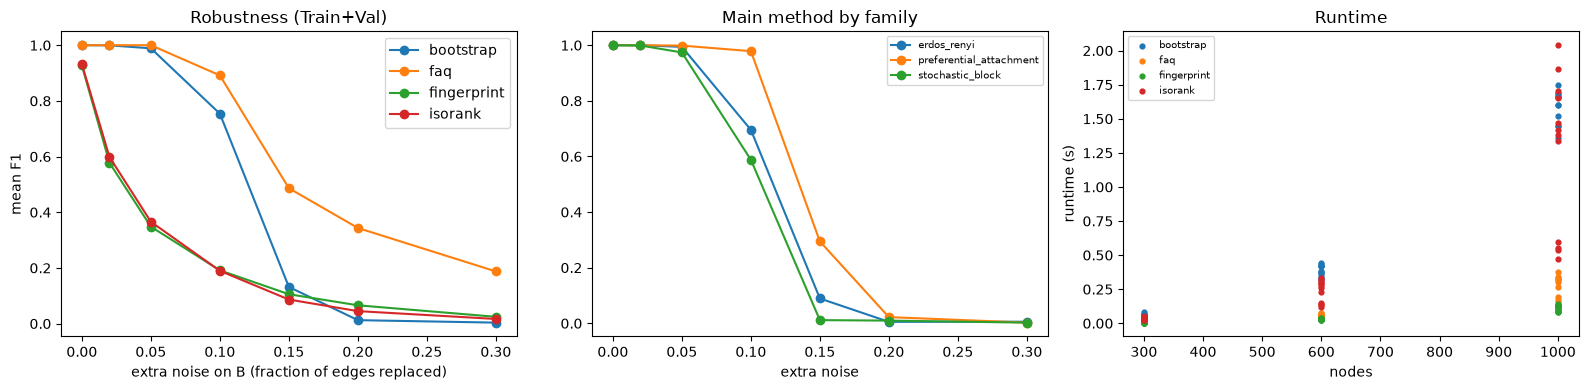

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for m, g in allr.groupby('method'):
    ax[0].plot(*zip(*g.groupby('noise').f1.mean().items()), marker='o', label=m)
ax[0].set_xlabel('extra noise on B (fraction of edges replaced)'); ax[0].set_ylabel('mean F1'); ax[0].legend(); ax[0].set_title('Robustness (Train+Val)')
for fam, g in allr[allr.method == 'bootstrap'].groupby('family'):
    ax[1].plot(*zip(*g.groupby('noise').f1.mean().items()), marker='o', label=fam)
ax[1].set_title('Main method by family'); ax[1].set_xlabel('extra noise'); ax[1].legend(fontsize=7)
for m, g in allr[allr.noise == 0].groupby('method'):
    ax[2].scatter(g.n, g.runtime, label=m, s=12)
ax[2].set_xlabel('nodes'); ax[2].set_ylabel('runtime (s)'); ax[2].set_title('Runtime'); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(RESULTS / 'figs' / 'robustness.png', dpi=130); plt.show()

## 7. Matching confidence (main method)
Accuracy of each matched pair as a function of its consistency votes, and the precision/coverage trade-off of the rejection threshold (Val, extra noise 5% and 10% where errors exist).

accuracy  pairs
noise bin                                  
0.05  (-1.0, 0.0]              0.000      2
      (0.0, 1.0]               0.000      5
      (1.0, 2.0]               0.000      4
      (2.0, 4.0]               0.838     37
      (4.0, 8.0]               0.985   1090
      (8.0, 16.0]              0.994    818
      (16.0, 1000000000.0]     0.999   3738
0.10  (-1.0, 0.0]              0.000      7
      (0.0, 1.0]               0.000      6
      (1.0, 2.0]               0.130     46
      (2.0, 4.0]               0.579    340
      (4.0, 8.0]               0.774   1425
      (8.0, 16.0]              0.454   1316
      (16.0, 1000000000.0]     0.881   2544

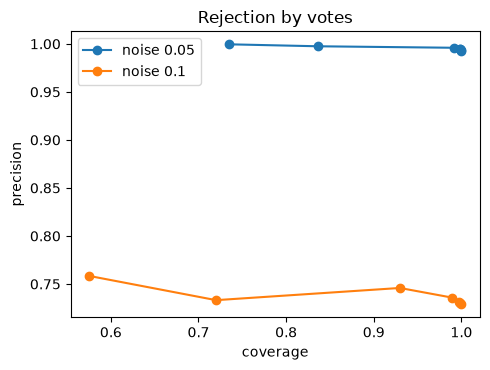

In [18]:
recs = []
for nm in list_instances('val'):
    A_, B_, tr_, mt_ = load_instance('val', nm)
    for z in (0.05, 0.10):
        Bz = perturb(B_, z, 0); p = match_bootstrap(A_, Bz, **best['bootstrap']['params']); c = consistency(A_, Bz, p)
        recs += [dict(inst=nm, family=mt_['family'], noise=z, votes=c[a], correct=tr_[a] == b) for a, b in p.items()]
cf = pd.DataFrame(recs); cf['bin'] = pd.cut(cf.votes, [-1, 0, 1, 2, 4, 8, 16, 1e9])
tb = cf.groupby(['noise', 'bin'], observed=True).correct.agg(['mean', 'size']).rename(columns={'mean': 'accuracy', 'size': 'pairs'})
display(tb.round(3))
fig, ax = plt.subplots(figsize=(5, 3.8))
for z, g in cf.groupby('noise'):
    pts = [(len(g[g.votes >= t]) / len(g), g[g.votes >= t].correct.mean()) for t in (0, 1, 2, 3, 5, 8, 12)]
    ax.plot(*zip(*pts), marker='o', label=f'noise {z}')
ax.set_xlabel('coverage'); ax.set_ylabel('precision'); ax.legend(); ax.set_title('Rejection by votes'); plt.tight_layout()
plt.savefig(RESULTS / 'figs' / 'confidence.png', dpi=130); plt.show()

## 8. Ablation: FAQ-seeded percolation (exploratory)
Question: is the main method's weakness under heavy noise only the seed source? Here the seeds come from FAQ (pairs whose consistency votes >= `seed_votes`) instead of fingerprints, then the same percolation + re-seed runs. Settings chosen on Train only; this does **not** change the frozen submission below.

In [19]:
def match_faq_perc(A, B, seed_votes=6, r=2, reseed_votes=4, init_lambda=0.5, iters=15):
    C = fingerprint_cost(A, B)
    p = match_faq(A, B, init_lambda=init_lambda, iters=iters, C=C)
    c = consistency(A, B, p)
    seeds = {a: b for a, b in p.items() if c[a] >= seed_votes}
    if not seeds:
        return p
    pred, votes = percolate(A, B, seeds, r=r, tiebreak=C)
    keep = {a: b for a, b in pred.items() if votes[a] >= reseed_votes}
    if keep and len(keep) < len(pred):
        pred, votes = percolate(A, B, keep, r=r, tiebreak=C)
    return pred
METHODS['faq_perc'] = match_faq_perc
abl_tbl, abl_best = tune('faq_perc', [dict(params=dict(seed_votes=sv, r=r)) for sv in (4, 8, 12) for r in (1, 2)], noises=[0.05, 0.10, 0.15])
display(abl_tbl.round(3)); print(abl_best)

,f1,precision,recall,coverage,runtime,f1@0.05,f1@0.1,f1@0.15
cfg,,,,,,,,
"{""params"": {""r"": 1, ""seed_votes"": 12}, ""tau"": 0}",0.810,0.810,0.810,1.000,0.536,1.0,0.892,0.538
"{""params"": {""r"": 2, ""seed_votes"": 12}, ""tau"": 0}",0.810,0.816,0.810,0.987,0.511,1.0,0.892,0.538
"{""params"": {""r"": 1, ""seed_votes"": 8}, ""tau"": 0}",0.796,0.796,0.796,1.000,0.513,1.0,0.892,0.496
"{""params"": {""r"": 2, ""seed_votes"": 8}, ""tau"": 0}",0.796,0.796,0.796,0.999,0.487,1.0,0.892,0.495
"{""params"": {""r"": 1, ""seed_votes"": 4}, ""tau"": 0}",0.795,0.795,0.795,1.000,0.476,1.0,0.892,0.494
"{""params"": {""r"": 2, ""seed_votes"": 4}, ""tau"": 0}",0.795,0.795,0.795,0.999,0.464,1.0,0.892,0.494


{'params': {'r': 1, 'seed_votes': 12}, 'tau': 0}


In [20]:
rows = Parallel(n_jobs=-1)(delayed(run_stress)('val', nm, m, (abl_best['params'] if m == 'faq_perc' else best[m]['params']), z, best[m].get('tau', 0) if m == 'bootstrap' else 0)
                           for nm in list_instances("val") for m in ('bootstrap', 'faq', 'faq_perc') for z in VAL_NOISE)
abl = pd.DataFrame(rows); abl.to_csv(RESULTS / 'ablation_val.csv', index=False)
display(Markdown('**Val: F1 vs extra noise (bootstrap = fingerprint seeds, faq_perc = FAQ seeds + percolation)**'))
display(abl.pivot_table(index='method', columns='noise', values='f1').round(3))
display(abl[abl.noise == 0.15].pivot_table(index='family', columns='method', values='f1').round(3))

**Val: F1 vs extra noise (bootstrap = fingerprint seeds, faq_perc = FAQ seeds + percolation)**

noise,0.00,0.02,0.05,0.10,0.15,0.20,0.30
method,,,,,,,
bootstrap,1.0,0.999,0.994,0.728,0.014,0.015,0.001
faq,1.0,1.000,1.000,0.891,0.464,0.343,0.139
faq_perc,1.0,1.000,1.000,0.891,0.521,0.335,0.222


method,bootstrap,faq,faq_perc
family,,,
erdos_renyi,0.006,0.034,0.010
preferential_attachment,0.032,1.000,1.000
stochastic_block,0.005,0.358,0.552


## 9. Test predictions (main method, frozen settings)

In [21]:
frozen = json.loads(Path('config.json').read_text()); mm = frozen['main_method']; prm = frozen['methods'][mm]
OUT = Path('predictions'); summ = []
for nm in list_instances('test'):
    A_, B_, _, mt_ = load_instance('test', nm); n_ = A_.shape[0]
    t = time.perf_counter(); p = reject(A_, B_, METHODS[mm](A_, B_, **prm['params']), prm.get('tau', 0)); dt = time.perf_counter() - t
    out = pd.DataFrame(sorted(p.items()), columns=['node_a', 'node_b'])
    assert out.node_a.is_unique and out.node_b.is_unique and out.node_a.between(0, n_ - 1).all() and out.node_b.between(0, n_ - 1).all(), nm
    (OUT / nm).mkdir(parents=True, exist_ok=True); out.to_csv(OUT / nm / 'predictions.csv', index=False)
    c = consistency(A_, B_, p)
    summ.append(dict(instance=nm, family=mt_['family'], difficulty=mt_['difficulty'], n=n_, predicted=len(out), coverage=len(out) / n_,
                     edge_overlap=np.mean(list(c.values())) / np.maximum(A_.sum() / n_, 1), runtime=dt))
ts = pd.DataFrame(summ); display(ts.round(3)); ts.to_csv(RESULTS / 'test_summary.csv', index=False)
print('wrote', len(ts), 'files')

,instance,family,difficulty,n,predicted,coverage,edge_overlap,runtime
0,erdos_renyi_easy_00,erdos_renyi,easy,300,300,1.0,1.000,0.056
1,erdos_renyi_easy_01,erdos_renyi,easy,300,300,1.0,1.000,0.054
2,erdos_renyi_hard_00,erdos_renyi,hard,1000,1000,1.0,0.995,1.256
3,erdos_renyi_hard_01,erdos_renyi,hard,1000,1000,1.0,0.995,1.275
4,erdos_renyi_medium_00,erdos_renyi,medium,600,600,1.0,0.997,0.307
5,erdos_renyi_medium_01,erdos_renyi,medium,600,600,1.0,0.997,0.308
6,preferential_attachment_easy_00,preferential_attachment,easy,300,300,1.0,0.999,0.049
7,preferential_attachment_easy_01,preferential_attachment,easy,300,300,1.0,0.999,0.052
8,preferential_attachment_hard_00,preferential_attachment,hard,1000,1000,1.0,0.994,1.111
9,preferential_attachment_hard_01,preferential_attachment,hard,1000,1000,1.0,0.994,1.147


wrote 18 files


In [22]:
for nm in list_instances('test'):
    d = pd.read_csv(OUT / nm / 'predictions.csv'); n_ = len(pd.read_csv(DATA / 'test' / nm / 'nodes_a.csv'))
    assert list(d.columns) == ['node_a', 'node_b'] and d.node_a.is_unique and d.node_b.is_unique
    assert d.node_a.between(0, n_ - 1).all() and d.node_b.between(0, n_ - 1).all()
print('OK:', len(list(OUT.glob('*/predictions.csv'))), 'files')

OK: 18 files
